In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch


# If needed, add src to sys.path (only if imports fail)
import sys
project_root = Path("..").resolve()
src_path = project_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))


from mlp_advanced import train_mlp_advanced  # from src/mlp_advanced.py


In [3]:
project_root = Path("..")
data_dir = project_root / "data"
processed_dir = data_dir / "processed"

# Load scaled features
X_train_scaled = np.load(processed_dir / "X_train_scaled.npy")
X_val_scaled = np.load(processed_dir / "X_val_scaled.npy")
X_test_int_scaled = np.load(processed_dir / "X_test_int_scaled.npy")
X_test_blind_scaled = np.load(processed_dir / "X_test_blind_scaled.npy")

# Load targets
y_train = np.load(processed_dir / "y_train.npy")
y_val = np.load(processed_dir / "y_val.npy")
y_test_int = np.load(processed_dir / "y_test_int.npy")

# Blind test IDs
ids_ts = np.load(processed_dir / "ids_ts.npy")

print("Train:", X_train_scaled.shape, y_train.shape)
print("Val:", X_val_scaled.shape, y_val.shape)
print("Internal test:", X_test_int_scaled.shape, y_test_int.shape)
print("Blind test:", X_test_blind_scaled.shape, ids_ts.shape)


Train: (300, 12) (300, 4)
Val: (100, 12) (100, 4)
Internal test: (100, 12) (100, 4)
Blind test: (1000, 12) (1000,)


In [4]:
# Stack all labeled data for final training
X_full = np.vstack([X_train_scaled, X_val_scaled, X_test_int_scaled])
y_full = np.vstack([y_train, y_val, y_test_int])

print("Full training set:", X_full.shape, y_full.shape)


Full training set: (500, 12) (500, 4)


In [5]:
def mee(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    diffs = y_pred - y_true
    dist = np.linalg.norm(diffs, axis=1)
    return float(np.mean(dist))


In [6]:
best_mlp_config = {
    "hidden_layers": [128, 64, 32],
    "lr": 0.0005,
    "weight_decay": 0.001,
    "batch_size": 64,
    "activation": "relu",
    "dropout": 0.0,
    "seed": 1,
}

best_mlp_config


{'hidden_layers': [128, 64, 32],
 'lr': 0.0005,
 'weight_decay': 0.001,
 'batch_size': 64,
 'activation': 'relu',
 'dropout': 0.0,
 'seed': 1}

In [7]:
mlp_final, history_final, val_mee_final = train_mlp_advanced(
    X_train=X_full,
    y_train=y_full,
    X_val=X_test_int_scaled,   # just used for early stopping metric
    y_val=y_test_int,
    hidden_layers=best_mlp_config["hidden_layers"],
    activation=best_mlp_config["activation"],
    lr=best_mlp_config["lr"],
    weight_decay=best_mlp_config["weight_decay"],
    dropout=best_mlp_config["dropout"],
    batch_size=int(best_mlp_config["batch_size"]),
    max_epochs=3000,
    patience=300,
    seed=int(best_mlp_config["seed"]),
    verbose=True   # you can set to False if too chatty
)

print("Final val MEE used for stopping:", val_mee_final)


Epoch 0 | Train MEE=34.8945, Val MEE=34.8894, LR=5.00e-04
Epoch 100 | Train MEE=23.0110, Val MEE=23.5343, LR=5.00e-04
Epoch 200 | Train MEE=21.2901, Val MEE=21.8821, LR=5.00e-04
Epoch 300 | Train MEE=19.9008, Val MEE=20.2189, LR=5.00e-04
Epoch 400 | Train MEE=19.0186, Val MEE=19.1436, LR=5.00e-04
Epoch 500 | Train MEE=18.3319, Val MEE=18.1702, LR=5.00e-04
Epoch 600 | Train MEE=17.7052, Val MEE=17.2479, LR=5.00e-04
Epoch 700 | Train MEE=17.0934, Val MEE=16.5433, LR=5.00e-04
Epoch 800 | Train MEE=16.5211, Val MEE=15.8390, LR=5.00e-04
Epoch 900 | Train MEE=15.9562, Val MEE=15.2792, LR=5.00e-04
Epoch 1000 | Train MEE=15.4398, Val MEE=14.8384, LR=5.00e-04
Epoch 1100 | Train MEE=15.0262, Val MEE=14.4999, LR=5.00e-04
Epoch 1200 | Train MEE=14.4821, Val MEE=14.0928, LR=5.00e-04
Epoch 1300 | Train MEE=13.9507, Val MEE=13.5243, LR=5.00e-04
Epoch 1400 | Train MEE=13.6461, Val MEE=13.2083, LR=5.00e-04
Epoch 1500 | Train MEE=13.1400, Val MEE=12.8571, LR=5.00e-04
Epoch 1600 | Train MEE=12.5705, Val 

In [8]:
X_full_t = torch.tensor(X_full, dtype=torch.float32)
with torch.no_grad():
    y_full_pred = mlp_final(X_full_t).cpu().numpy()

print("MEE on full labeled set:", mee(y_full, y_full_pred))


MEE on full labeled set: 9.491815848577113


In [9]:
X_blind_t = torch.tensor(X_test_blind_scaled, dtype=torch.float32)
with torch.no_grad():
    y_blind_pred = mlp_final(X_blind_t).cpu().numpy()

print("Blind predictions shape:", y_blind_pred.shape)


Blind predictions shape: (1000, 4)


In [10]:
submission_df = pd.DataFrame({
    "id": ids_ts.astype(int),
    "t1": y_blind_pred[:, 0],
    "t2": y_blind_pred[:, 1],
    "t3": y_blind_pred[:, 2],
    "t4": y_blind_pred[:, 3],
})

submission_df.head()


,id,t1,t2,t3,t4
0,1,-1.730436,-11.860144,11.765870,-2.527109
1,2,-3.723773,-9.688217,-40.911057,14.601904
2,3,-8.035935,0.164716,-8.000319,4.575934
3,4,-9.323388,-16.417425,-33.658840,3.663034
4,5,9.927461,-16.229794,-29.157032,18.420980


In [11]:
output_path = project_root / "Palestine_ML-CUP25-TS.csv"
submission_df.to_csv(output_path, index=False)

print("Saved submission file to:", output_path)


Saved submission file to: ..\Palestine_ML-CUP25-TS.csv


In [12]:
import matplotlib.pyplot as plt

def plot_cup_learning_curves(history, title="CUP – MLP Learning Curve"):
    epochs = range(len(history["train_mee"]))

    plt.figure(figsize=(10,5))

    plt.plot(epochs, history["train_mee"], label="Train MEE", linewidth=2)
    plt.plot(epochs, history["val_mee"], label="Val MEE", linewidth=2)

    plt.title(title, fontsize=16)
    plt.xlabel("Epoch", fontsize=14)
    plt.ylabel("MEE", fontsize=14)
    plt.grid(True)
    plt.legend(fontsize=12)
    plt.show()


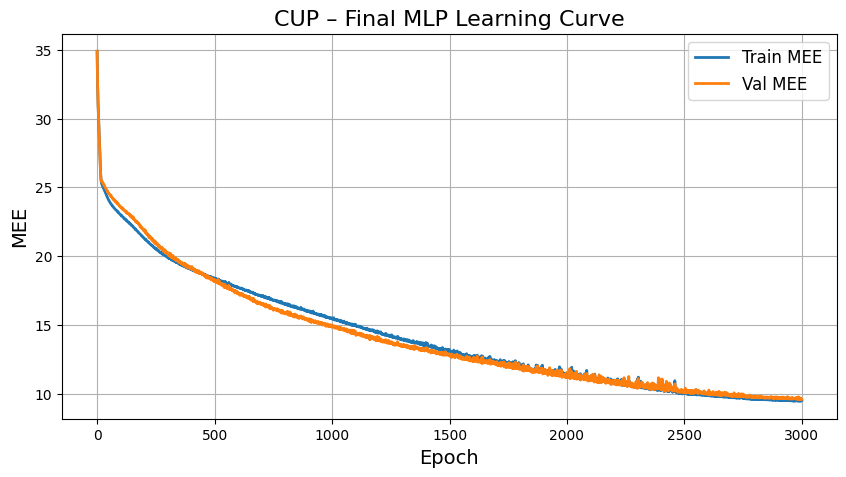

In [15]:
plot_cup_learning_curves(history_final, "CUP – Final MLP Learning Curve")

